## Proyecto ML

**INTEGRANTES**

- Luis Alfredo suarez chinchilla
- Cristian David Acevedo Hernandez
- Eric Adrian Mendez Ojeda


# Predicción de accesos fijos a Internet en Colombia — Random Forest





## Problema de investigación

En Colombia, la calidad del internet fijo no es igual en todo el territorio.
¿En qué departamentos se contratan las mayores velocidades de bajada y subida,
y qué tanto dependen esas velocidades del estrato socioeconómico y de la
tecnología de acceso?

## Objetivo general

Identificar los departamentos con mejor internet fijo y determinar qué factores
(ubicación, estrato y tecnología) explican las diferencias de velocidad,
mediante un modelo de regresión lineal.

## Preguntas específicas

1. ¿Qué departamentos tienen la mayor velocidad promedio de bajada y de subida,
   ponderada por número de accesos?
2. ¿Cómo cambia la velocidad contratada entre estratos 1 a 6 en el segmento
   residencial?
3. ¿Qué tecnología (fibra óptica, cable, WiFi, etc.) se asocia con mayores
   velocidades, una vez se controla por departamento y estrato?
4. ¿Qué pesa más para explicar la velocidad: el departamento, el estrato o la
   tecnología?
5. ¿Cómo evolucionó la velocidad promedio entre 2023 y 2026, y se redujo la
   brecha entre departamentos?

## Variable a predecir (Y)

VELOCIDAD_BAJADA (Mbps).

## Variables explicativas (X)

DEPARTAMENTO, ESTRATO, TECNOLOGIA, ANNO, TRIMESTRE

## Tipo de aprendizaje

Supervisado

## Tipo de problema

Regresión

## Algoritmo

Random Forest Regressor (bosque aleatorio) con variables categóricas codificadas (one-hot), entrenado con ponderación por accesos fijos a Internet.

In [10]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

archivo = "Accesos_a_Internet_corregido.csv"
if not os.path.exists(archivo):
    from google.colab import files
    files.upload()
df = pd.read_csv(archivo)
display(df.head())
print("Datos cargados:", df.shape)

,ANNO,TRIMESTRE,PROVEEDOR,CODIGO_DANE_DEPARTAMENTO,DEPARTAMENTO,CODIGO_DANE_MUNICIPIO,MUNICIPIO,SEGMENTO,TECNOLOGIA,VELOCIDAD_BAJADA,VELOCIDAD_SUBIDA,ACCESOS_FIJOS_INTERNET
0,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),50.0,25.0,1
1,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),40.0,20.0,4
2,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),15.0,7.5,5
3,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),30.0,15.0,4
4,2023,4,SOMOS TV+INTERNET SAS,19,CAUCA,19698,SANTANDER DE QUILICHAO,RESIDENCIAL - ESTRATO 2,FIBER TO THE HOME (FTTH),20.0,10.0,4


Datos cargados: (2072381, 12)


## Preparación

In [12]:
cols = ["ANNO","TRIMESTRE","DEPARTAMENTO","TECNOLOGIA","SEGMENTO","VELOCIDAD_BAJADA","VELOCIDAD_SUBIDA","ACCESOS_FIJOS_INTERNET"]
df = df[cols].dropna()
df = df[df["SEGMENTO"].str.contains("RESIDENCIAL", case=False)].copy()
df["ESTRATO"] = df["SEGMENTO"].str.extract(r"ESTRATO\s*(\d)")[0]
df = df.dropna(subset=["ESTRATO"])
df["ESTRATO"] = df["ESTRATO"].astype(int)
df = df[(df["VELOCIDAD_BAJADA"] > 0) & (df["VELOCIDAD_BAJADA"] <= 1000) & (df["ACCESOS_FIJOS_INTERNET"] > 0)]
display(df.head())
print(df.shape)

,ANNO,TRIMESTRE,DEPARTAMENTO,TECNOLOGIA,SEGMENTO,VELOCIDAD_BAJADA,VELOCIDAD_SUBIDA,ACCESOS_FIJOS_INTERNET,ESTRATO
0,2023,4,CAUCA,FIBER TO THE HOME (FTTH),RESIDENCIAL - ESTRATO 2,50.0,25.0,1,2
1,2023,4,CAUCA,FIBER TO THE HOME (FTTH),RESIDENCIAL - ESTRATO 2,40.0,20.0,4,2
2,2023,4,CAUCA,FIBER TO THE HOME (FTTH),RESIDENCIAL - ESTRATO 2,15.0,7.5,5,2
3,2023,4,CAUCA,FIBER TO THE HOME (FTTH),RESIDENCIAL - ESTRATO 2,30.0,15.0,4,2
4,2023,4,CAUCA,FIBER TO THE HOME (FTTH),RESIDENCIAL - ESTRATO 2,20.0,10.0,4,2


(1428480, 9)


Después de dejar solo el segmento residencial, extraer el estrato y filtrar velocidades entre 0 y 1000 Mbps con accesos mayores a cero, quedaron 1,428,480 filas y 9 columnas, se conservó cerca del 69 % de los datos, y las 9 columnas son las 8 seleccionadas más ESTRATO, la vista previa muestra registros de Cauca en 2023 con fibra FTTH y estrato 2, con velocidades de 15 a 50 Mbps de bajada y la mitad en subida.

## Análisis ponderado por accesos

In [4]:
def pond(d, por, col):
    t = d.assign(_p=d[col]*d["ACCESOS_FIJOS_INTERNET"]).groupby(por)[["_p","ACCESOS_FIJOS_INTERNET"]].sum()
    return (t["_p"]/t["ACCESOS_FIJOS_INTERNET"]).rename(col)

dsub = df[(df["VELOCIDAD_SUBIDA"] > 0) & (df["VELOCIDAD_SUBIDA"] <= 1000)]
print("P1 - Bajada por departamento (top 10)");  print(pond(df,"DEPARTAMENTO","VELOCIDAD_BAJADA").sort_values(ascending=False).head(10).round(2))
print("\nP1 - Subida por departamento (top 10)"); print(pond(dsub,"DEPARTAMENTO","VELOCIDAD_SUBIDA").sort_values(ascending=False).head(10).round(2))
print("\nP2 - Bajada por estrato");  print(pond(df,"ESTRATO","VELOCIDAD_BAJADA").round(2))
print("\nP2 - Subida por estrato");  print(pond(dsub,"ESTRATO","VELOCIDAD_SUBIDA").round(2))

# P5: promedio por año y brecha entre departamentos
print("\nP5 - Bajada por año"); print(pond(df,"ANNO","VELOCIDAD_BAJADA").round(2))
dd = pond(df,["ANNO","DEPARTAMENTO"],"VELOCIDAD_BAJADA").reset_index()
print("\nP5 - Brecha entre departamentos por año (desv. estándar y rango)")
print(dd.groupby("ANNO")["VELOCIDAD_BAJADA"].agg(desv="std", rango=lambda s: s.max()-s.min()).round(2))

P1 - Bajada por departamento (top 10)
DEPARTAMENTO
ATLÁNTICO          483.99
BOGOTÁ D.C.        475.46
SANTANDER          448.46
BOLÍVAR            426.99
META               405.88
ANTIOQUIA          402.79
VALLE DEL CAUCA    393.31
CUNDINAMARCA       387.55
QUINDÍO            373.62
RISARALDA          366.48
Name: VELOCIDAD_BAJADA, dtype: float64

P1 - Subida por departamento (top 10)
DEPARTAMENTO
ATLÁNTICO                                                   358.86
ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANTA CATALINA    325.67
BOGOTÁ D.C.                                                 320.35
SANTANDER                                                   312.39
BOLÍVAR                                                     297.50
META                                                        271.64
CUNDINAMARCA                                                269.22
VALLE DEL CAUCA                                             258.33
CESAR                                                       23

Por departamento, Atlántico, Bogotá y Santander tienen las mayores velocidades de bajada y subida, las velocidades de subida son menores que las de bajada en todos los casos. Por estrato, la velocidad sube del estrato 1 al 5 y baja un poco en el 6, por año, la velocidad promedio sube cada año, de 225 a 504 Mbps. La brecha entre departamentos crece, la desviación estándar pasó de 83 a 181 Mbps y el rango de 276 a 603 Mbps.

## Gráficas del análisis

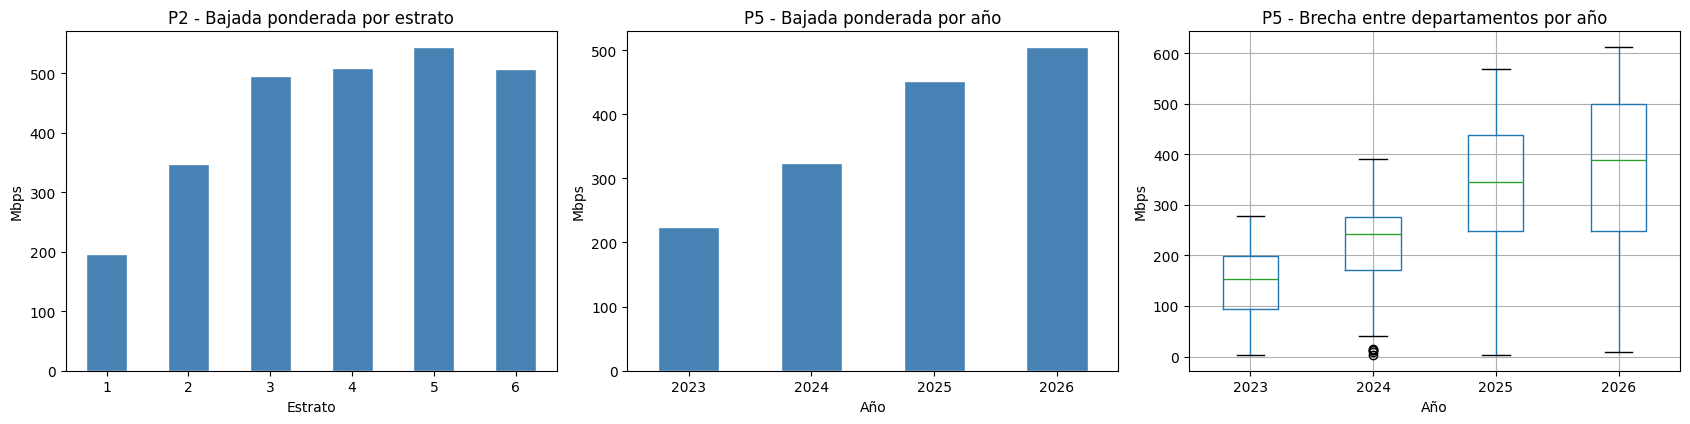

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

# P2: barras por estrato
pond(df,"ESTRATO","VELOCIDAD_BAJADA").plot(kind="bar", ax=axes[0], color="steelblue", edgecolor="white")
axes[0].set_title("P2 - Bajada ponderada por estrato"); axes[0].set_xlabel("Estrato"); axes[0].set_ylabel("Mbps")
axes[0].tick_params(axis="x", rotation=0)

# P5: barras por año
pond(df,"ANNO","VELOCIDAD_BAJADA").plot(kind="bar", ax=axes[1], color="steelblue", edgecolor="white")
axes[1].set_title("P5 - Bajada ponderada por año"); axes[1].set_xlabel("Año"); axes[1].set_ylabel("Mbps")
axes[1].tick_params(axis="x", rotation=0)

# P5: boxplot de los promedios departamentales por año (la altura de la caja es la brecha)
dd.boxplot(column="VELOCIDAD_BAJADA", by="ANNO", ax=axes[2])
axes[2].set_title("P5 - Brecha entre departamentos por año"); axes[2].set_xlabel("Año"); axes[2].set_ylabel("Mbps")

plt.suptitle(""); plt.tight_layout(); plt.show()

Las barras por estrato muestran un salto fuerte entre los estratos 1 y 3 y un cambio casi nulo desde el 4, las barras por año muestran un crecimiento continuo, en el boxplot por año las cajas se hacen más altas, lo que confirma que la brecha entre departamentos se ensancha y bueno en 2024 aparecen algunos valores atípicos cercanos a cero.

## Codificación y partición

In [17]:
dummies = pd.get_dummies(df[["DEPARTAMENTO","TECNOLOGIA"]], dtype=np.int8)
X = pd.concat([df[["ANNO","TRIMESTRE","ESTRATO"]].astype("float32"), dummies], axis=1)
y = df["VELOCIDAD_BAJADA"].values
w = df["ACCESOS_FIJOS_INTERNET"].values

display(X.head())

X_tr, X_te, y_tr, y_te, w_tr, w_te = train_test_split(X, y, w, test_size=0.2, random_state=42)

print("Datos de entrenamiento:", X_tr.shape, y_tr.shape, w_tr.shape)
print("Datos de prueba:", X_te.shape, y_te.shape, w_te.shape)

,ANNO,TRIMESTRE,ESTRATO,DEPARTAMENTO_AMAZONAS,DEPARTAMENTO_ANTIOQUIA,DEPARTAMENTO_ARAUCA,"DEPARTAMENTO_ARCHIPIÉLAGO DE SAN ANDRÉS, PROVIDENCIA Y SANTA CATALINA",DEPARTAMENTO_ATLÁNTICO,DEPARTAMENTO_BOGOTÁ D.C.,DEPARTAMENTO_BOLÍVAR,...,TECNOLOGIA_HYBRID FIBER COAXIAL (HFC),TECNOLOGIA_NA (NO APLICA),TECNOLOGIA_OTRAS TECNOLOGÍAS DE FIBRA (ANTES FTTX),TECNOLOGIA_OTRAS TECNOLOGÍAS FIJAS,TECNOLOGIA_OTRAS TECNOLOGÍAS INALÁMBRICAS,TECNOLOGIA_SATELITAL,TECNOLOGIA_SATELITAL LEO,TECNOLOGIA_WIFI,TECNOLOGIA_WIMAX,TECNOLOGIA_XDSL
0,2023.0,4.0,2.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2023.0,4.0,2.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2023.0,4.0,2.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,2023.0,4.0,2.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,2023.0,4.0,2.0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Datos de entrenamiento: (1142784, 54) (1142784,) (1142784,)
Datos de prueba: (285696, 54) (285696,) (285696,)


Con el One-Hot, las 5 variables explicativas se convirtieron en 54 columnas, se entrenó con 1,142,784 registros (80 %) y se probó con 285,696 (20 %), con los mismos números en X, y y los pesos.

## Random Forest

In [18]:
rf = RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=5,
                           max_samples=0.8, n_jobs=-1, random_state=42)
rf.fit(X_tr, y_tr, sample_weight=w_tr)

base = DummyRegressor(strategy="mean").fit(X_tr, y_tr, sample_weight=w_tr)

def metricas(m, nombre):
    p = m.predict(X_te)
    return {"Modelo":nombre, "MAE":mean_absolute_error(y_te,p,sample_weight=w_te),
            "RMSE":np.sqrt(mean_squared_error(y_te,p,sample_weight=w_te)),
            "R2":r2_score(y_te,p,sample_weight=w_te)}
print(pd.DataFrame([metricas(base,"Base (media)"), metricas(rf,"Random Forest")]).round(3).to_string(index=False))

       Modelo     MAE    RMSE     R2
 Base (media) 236.821 284.662 -0.001
Random Forest 178.621 234.621  0.320


El modelo obtiene R² de 0.320, MAE de 178.621 y RMSE de 234.621 Mbps, la línea base tiene R² de  -0.001, MAE de 236.821 y RMSE de 284.662. El Random Forest reduce el error, pero explica cerca de un tercio de la variación de la velocidad.

## Importancia por grupo  y efecto de la tecnología

P4 - Caída de R2 al permutar cada grupo (mayor = más peso)
TECNOLOGIA      0.6274
ESTRATO         0.3131
TIEMPO          0.1999
DEPARTAMENTO    0.0810
dtype: float64


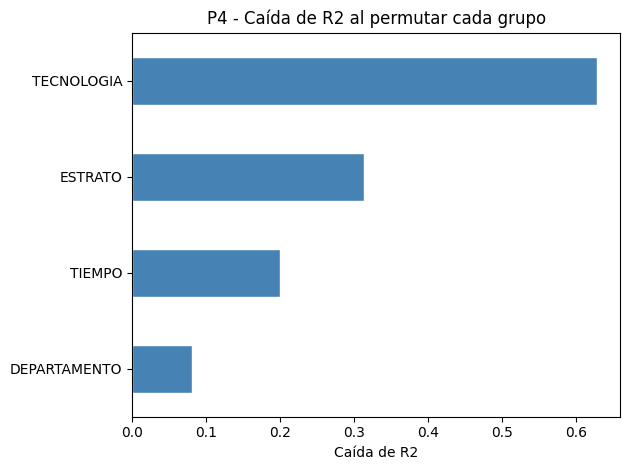


P3 - Bajada predicha (Mbps) según tecnología, controlando departamento y estrato
FIBER TO THE HOME (FTTH)                                432.60
FIBER TO THE BUILDING O FIBER TO THE BASEMENT (FTTB)    364.01
HYBRID FIBER COAXIAL (HFC)                              356.19
OTRAS TECNOLOGÍAS DE FIBRA (ANTES FTTX)                 155.19
FIBER TO THE PREMISES                                   140.39
5G FWA                                                  135.46
FIBER TO THE NODE (FTTN)                                121.60
OTRAS TECNOLOGÍAS FIJAS                                  75.37
FIBER TO THE ANTENNA (FTTA)                              67.74
NA (NO APLICA)                                           67.55
SATELITAL LEO                                            67.49
SATELITAL                                                63.48
CABLE                                                    57.97
FIBER TO THE CABINET (FTTC)                              57.74
WIMAX                               

In [19]:
rng = np.random.default_rng(42)
idx = rng.choice(len(X_te), size=min(50000, len(X_te)), replace=False)
Xs, ys, ws = X_te.iloc[idx], y_te[idx], w_te[idx]
r2_full = r2_score(ys, rf.predict(Xs), sample_weight=ws)

grupos = {"DEPARTAMENTO":[c for c in X.columns if c.startswith("DEPARTAMENTO_")],
          "ESTRATO":["ESTRATO"],
          "TECNOLOGIA":[c for c in X.columns if c.startswith("TECNOLOGIA_")],
          "TIEMPO":["ANNO","TRIMESTRE"]}
res = {}
for g, cs in grupos.items():
    caidas = []
    for _ in range(3):
        Xp = Xs.copy()
        Xp[cs] = Xs[cs].values[rng.permutation(len(Xs))]
        caidas.append(r2_full - r2_score(ys, rf.predict(Xp), sample_weight=ws))
    res[g] = np.mean(caidas)
print("P4 - Caída de R2 al permutar cada grupo (mayor = más peso)")
print(pd.Series(res).sort_values(ascending=False).round(4))

pd.Series(res).sort_values().plot(kind="barh", color="steelblue", edgecolor="white")
plt.title("P4 - Caída de R2 al permutar cada grupo"); plt.xlabel("Caída de R2"); plt.tight_layout(); plt.show()


# P3: velocidad predicha si todos tuvieran cada tecnología (controla depto y estrato)
tcols = grupos["TECNOLOGIA"]
efecto = {}
for c in tcols:
    Xc = Xs.copy(); Xc[tcols] = 0; Xc[c] = 1
    efecto[c.replace("TECNOLOGIA_","")] = np.average(rf.predict(Xc), weights=ws)
print("\nP3 - Bajada predicha (Mbps) según tecnología, controlando departamento y estrato")
print(pd.Series(efecto).sort_values(ascending=False).round(2))

Al mezclar cada grupo, el R² cae más con la tecnología (0.6274), luego con el estrato (0.3131), el tiempo (0.1999) y el departamento (0.0810), la tecnología es el factor que más pesa en la predicción, y el departamento el que menos.

Con departamento y estrato controlados, FTTH (432.60 Mbps), FTTB (364.1 Mbps) y HFC (356.19 Mbps) lideran, XDSL (8.24 Mbps), WiFi (18.60 Mbps) y WiMAX (49.15 Mbps) quedan al final, las tecnologías con pocos registros pueden dar valores menos confiables.

## Real vs. predicho

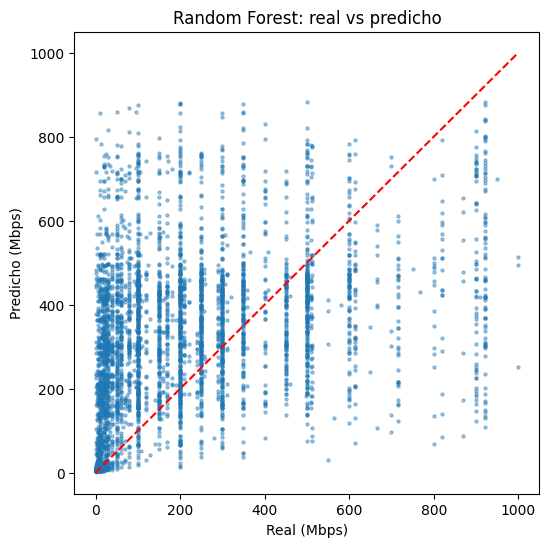

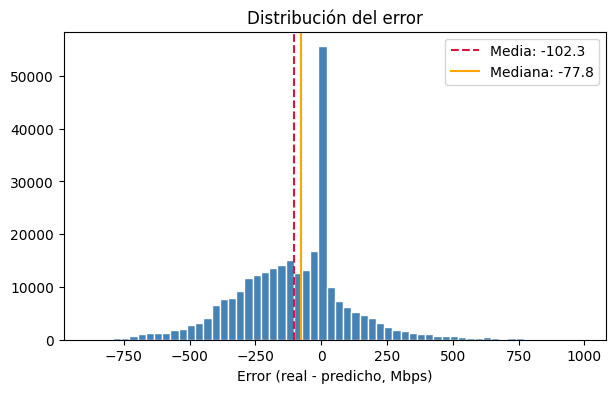

In [21]:
p = rf.predict(X_te)
plt.figure(figsize=(6,6)); plt.scatter(y_te[:5000], p[:5000], s=5, alpha=.4)
plt.plot([0,1000],[0,1000],"r--"); plt.xlabel("Real (Mbps)"); plt.ylabel("Predicho (Mbps)"); plt.title("Random Forest: real vs predicho"); plt.show()

error = y_te - p
plt.figure(figsize=(7,4)); plt.hist(error, bins=60, color="steelblue", edgecolor="white")
plt.axvline(error.mean(), color="crimson", linestyle="--", label=f"Media: {error.mean():.1f}")
plt.axvline(np.median(error), color="orange", label=f"Mediana: {np.median(error):.1f}")
plt.xlabel("Error (real - predicho, Mbps)"); plt.title("Distribución del error"); plt.legend(); plt.show()

##**Real vs predicho**

Los puntos forman columnas verticales porque las velocidades reales son planes comerciales fijos (50, 100, 200 Mbps etc), para un mismo plan, el modelo predice valores muy dispersos y no sigue bien la diagonal, se acerca más en velocidades bajas y falla más en las altas.

##**Dsitribuscion de error**

El error (real menos predicho) tiene una media de −101 Mbps y una mediana de −77 Mbps, es decir el modelo tiende a predecir velocidades más altas que las reales, el pico en cero indica que una buena parte de los casos se predice con muy poco error, aunque hay una cola larga hacia errores negativos de hasta −750 Mbps.

1. ¿Qué departamentos tienen la mayor velocidad promedio de bajada y de subida,
   ponderada por número de accesos?

   - En bajada lideran Atlántico (484 Mbps), Bogotá (475 Mbps) y Santander (448 Mbps), seguidos de Bolívar, Meta y Antioquia, en subida el orden es similar, Atlántico (359 Mbps), San Andrés (326 Mbps), Bogotá (320 Mbps) y Santander (312 Mbps). Los mismos departamentos aparecen arriba en ambas velocidades, lo que indica que la ventaja es de infraestructura y no de una sola métrica.

2. ¿Cómo cambia la velocidad contratada entre estratos 1 a 6 en el segmento
   residencial?
   
   - La velocidad sube con el estrato hasta el 5, en bajada pasa de 196 Mbps en el estrato 1 a 347 en el 2, 496 en el 3, 509 en el 4 y 544 en el 5, el estrato 6 baja un poco (507), en subida ocurre lo mismo, de 128 a 378 Mbps. El salto más grande está entre los estratos 1 a 3, y a partir del 4 la velocidad casi se estabiliza.

3. ¿Qué tecnología (fibra óptica, cable, WiFi, etc.) se asocia con mayores
   velocidades, una vez se controla por departamento y estrato?
   
   - Con departamento y estrato controlados, las mayores velocidades predichas son de FTTH (432.60 Mbps), FTTB (364.1 Mbps) y HFC (356.19 Mbps), las más bajas son XDSL (8.24 Mbps), WiFi (18.60 Mbps) y WiMAX (49.15 Mbps), cable queda en 58 Mbps, muy por debajo de la fibra. Las tecnologías con pocos registros, como las satelitales o “otras”, no se pudo saber nada completamente estimable asi que no se toman mucho en cuenta.

4. ¿Qué pesa más para explicar la velocidad: el departamento, el estrato o la
   tecnología?
   
   - La tecnología es el grupo con más peso, al mezclarla el R² cae (0.6274). Le siguen estrato (0.3131), tiempo (0.1999) y departamento (0.081), es decir, importa más con qué tecnología se conecta una persona y su estrato que dónde vive.

5. ¿Cómo evolucionó la velocidad promedio entre 2023 y 2026, y se redujo la
   brecha entre departamentos?
   
   - La velocidad promedio ponderada subió cada año: 225 Mbps en 2023, 324 en 2024, 452 en 2025 y 504 en 2026, la brecha entre departamentos, en cambio, se amplió, la desviación estándar pasó de 83 a 181 Mbps y el rango de 276 a 603 Mbps, el boxplot lo muestra con cajas cada vez más altas.

##**Conclucion**


La velocidad de bajada en Colombia depende sobre todo de la tecnología y del estrato, y mucho menos del departamento. La fibra (FTTH y FTTB) y HFC se asocian a las mayores velocidades, mientras que XDSL, WiFi y WiMAX quedan muy por debajo. El estrato 1 contrata velocidades mucho menores que los demás, y desde el estrato 4 se estabilizan. Atlántico, Bogotá y Santander concentran las mayores velocidades. Entre 2023 y 2026 la velocidad promedio más que se duplicó, pero el crecimiento no fue parejo: la brecha entre departamentos aumentó en lugar de reducirse. El modelo logra un R² de 0.321, suficiente para identificar qué factores pesan más, pero no para predecir con precisión la velocidad de cada caso. Eso se explica porque las velocidades son planes discretos y porque faltan variables como el proveedor o el municipio.